In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [7]:
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AAPL.csv.xls")
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2014-09-29,100.589996,100.690002,98.040001,99.620003,93.514290,142718700
1,2014-10-06,99.949997,102.379997,98.309998,100.730003,94.556244,280258200
2,2014-10-13,101.330002,101.779999,95.180000,97.669998,91.683792,358539800
3,2014-10-20,98.320000,105.489998,98.220001,105.220001,98.771042,358532900
4,2014-10-27,104.849998,108.040001,104.699997,108.000000,101.380676,220230600


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       184 non-null    object 
 1   Open       184 non-null    float64
 2   High       184 non-null    float64
 3   Low        184 non-null    float64
 4   Close      184 non-null    float64
 5   Adj Close  184 non-null    float64
 6   Volume     184 non-null    int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 10.2+ KB


In [9]:
data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [10]:
data["Date"] = pd.to_datetime(data["Date"])

data = data.sort_values("Date")

data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2014-09-29,100.589996,100.690002,98.040001,99.620003,93.514290,142718700
1,2014-10-06,99.949997,102.379997,98.309998,100.730003,94.556244,280258200
2,2014-10-13,101.330002,101.779999,95.180000,97.669998,91.683792,358539800
3,2014-10-20,98.320000,105.489998,98.220001,105.220001,98.771042,358532900
4,2014-10-27,104.849998,108.040001,104.699997,108.000000,101.380676,220230600


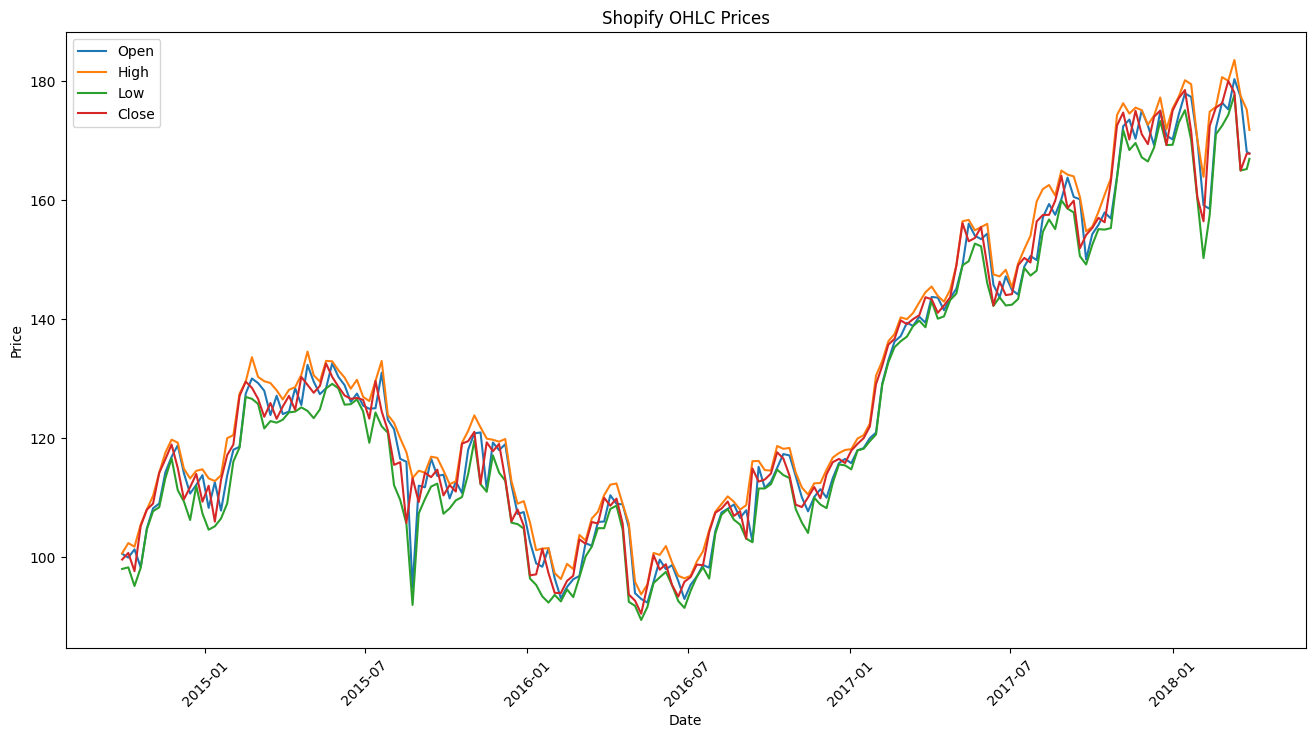

In [11]:
plt.figure(figsize=(16, 8))

plt.plot(data["Date"], data["Open"], label="Open")
plt.plot(data["Date"], data["High"], label="High")
plt.plot(data["Date"], data["Low"], label="Low")
plt.plot(data["Date"], data["Close"], label="Close")

plt.title("Shopify OHLC Prices")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)
plt.show()

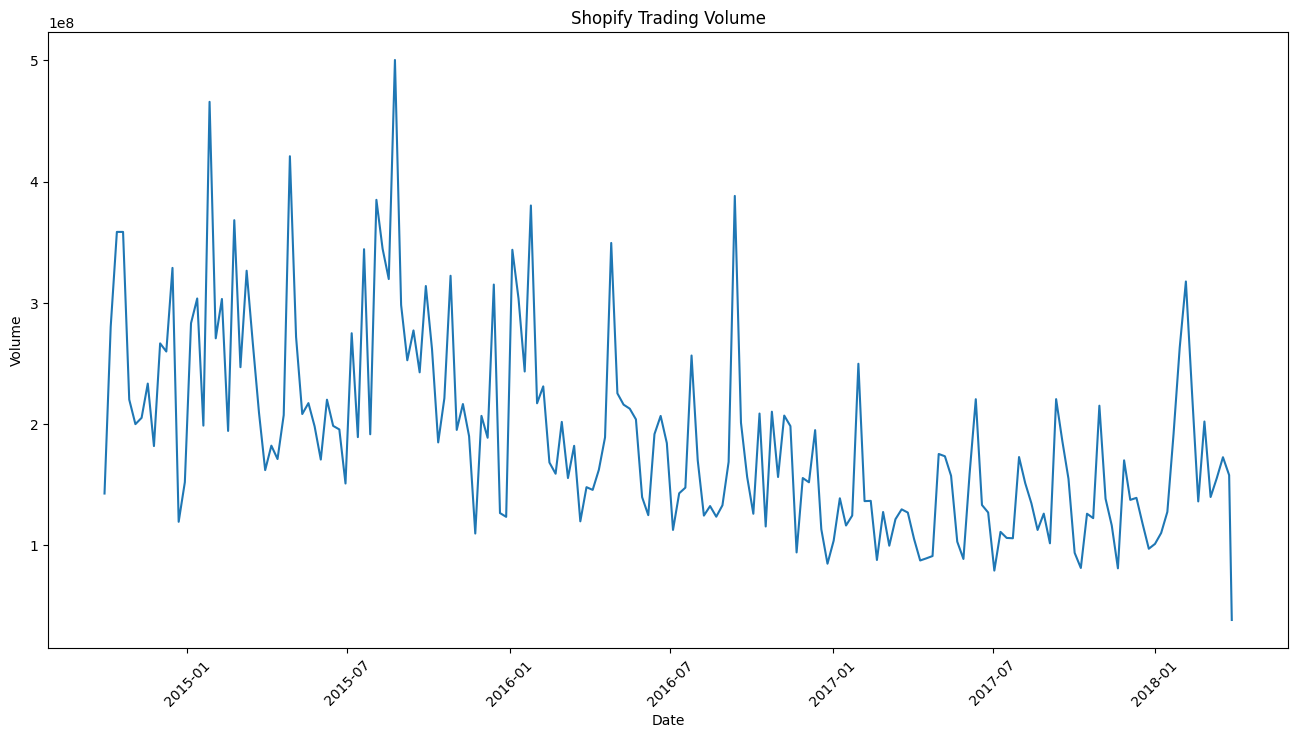

In [12]:
plt.figure(figsize=(16, 8))

plt.plot(data["Date"], data["Volume"])

plt.title("Shopify Trading Volume")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.xticks(rotation=45)
plt.show()

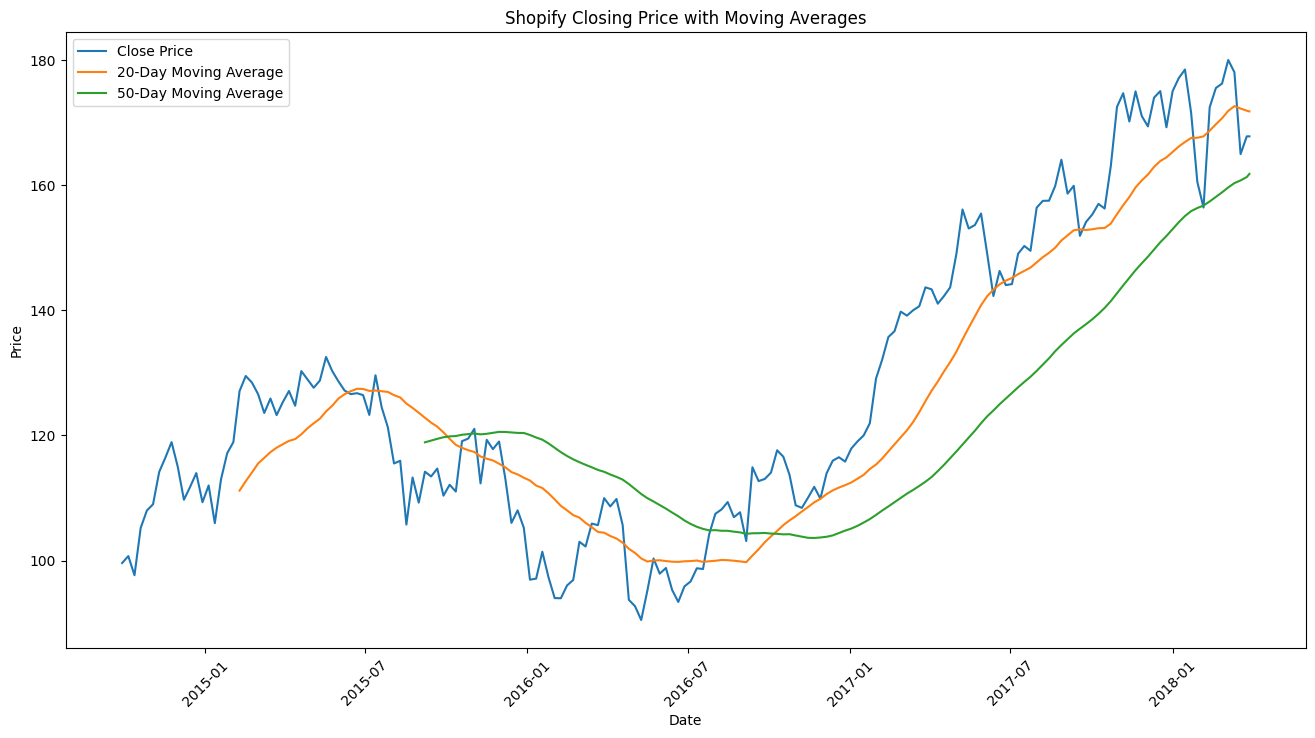

In [13]:
data["MA20"] = data["Close"].rolling(window=20).mean()
data["MA50"] = data["Close"].rolling(window=50).mean()

plt.figure(figsize=(16, 8))

plt.plot(data["Date"], data["Close"], label="Close Price")
plt.plot(data["Date"], data["MA20"], label="20-Day Moving Average")
plt.plot(data["Date"], data["MA50"], label="50-Day Moving Average")

plt.title("Shopify Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [14]:
data["Daily_Return"] = data["Close"].pct_change()

data[["Date", "Close", "Daily_Return"]].head()

,Date,Close,Daily_Return
0,2014-09-29,99.620003,NaN
1,2014-10-06,100.730003,0.011142
2,2014-10-13,97.669998,-0.030378
3,2014-10-20,105.220001,0.077301
4,2014-10-27,108.000000,0.026421


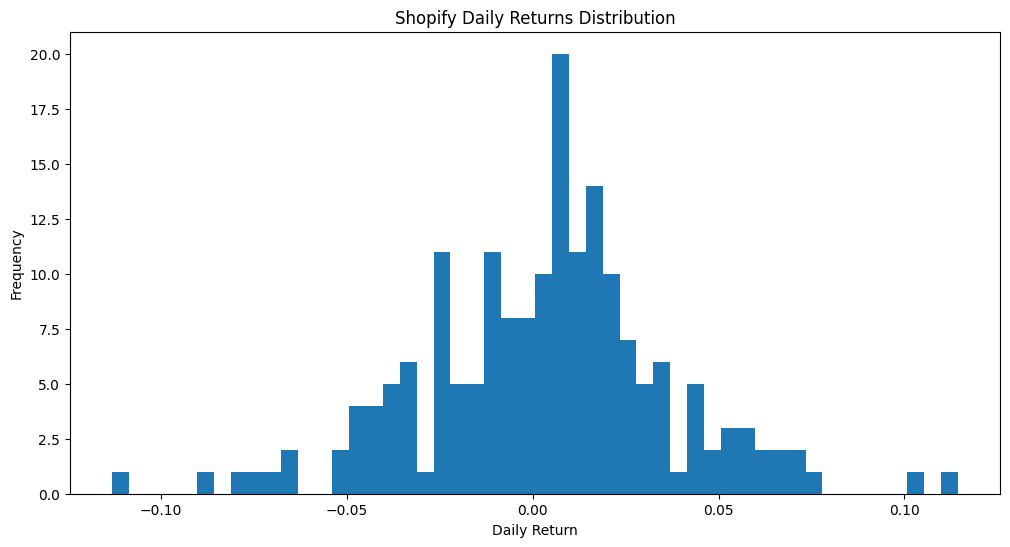

In [15]:
plt.figure(figsize=(12, 6))

plt.hist(data["Daily_Return"].dropna(), bins=50)

plt.title("Shopify Daily Returns Distribution")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()

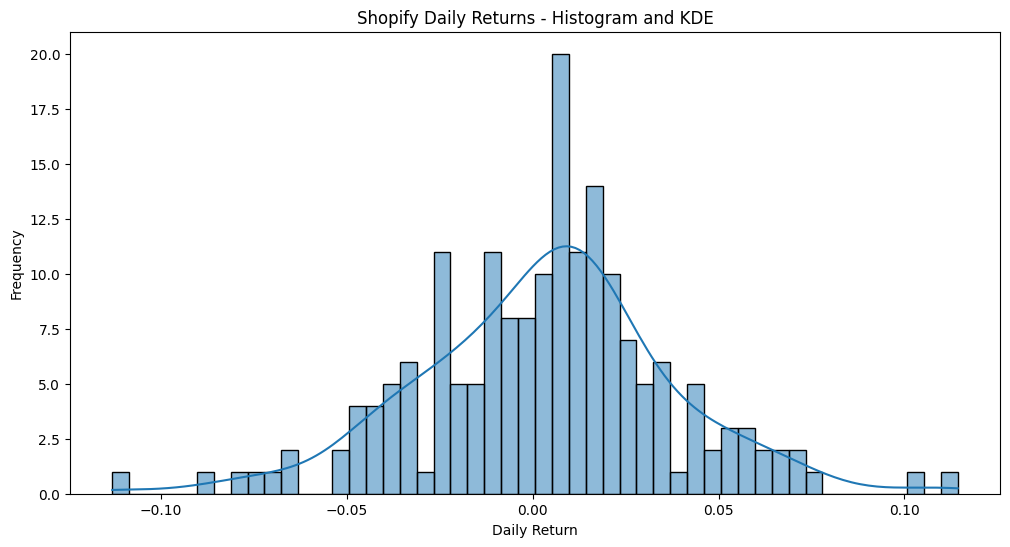

In [16]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data["Daily_Return"].dropna(),
    bins=50,
    kde=True
)

plt.title("Shopify Daily Returns - Histogram and KDE")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()

In [17]:
mean_return = data["Daily_Return"].mean()
variance_return = data["Daily_Return"].var()
std_return = data["Daily_Return"].std()

print("Mean Return:", mean_return)
print("Variance:", variance_return)
print("Standard Deviation:", std_return)

Mean Return: 0.0034279419287477123
Variance: 0.001156582992827167
Standard Deviation: 0.034008572343266145


In [18]:
volatility_limit = data["Daily_Return"].std()

high_volatility = data[
    data["Daily_Return"].abs() > volatility_limit
]

high_volatility[["Date", "Close", "Daily_Return"]]

,Date,Close,Daily_Return
3,2014-10-20,105.220001,0.077301
6,2014-11-10,114.180000,0.047427
10,2014-12-08,109.730003,-0.045826
13,2014-12-29,109.330002,-0.040881
15,2015-01-12,105.989998,-0.053745
16,2015-01-19,112.980003,0.065950
17,2015-01-26,117.160004,0.036998
19,2015-02-09,127.080002,0.068528
29,2015-04-20,130.279999,0.044329
41,2015-07-13,129.619995,0.051428


In [19]:
print("FINANCIAL SUMMARY")
print("----------------------------")

print("Average Daily Return:", data["Daily_Return"].mean())
print("Return Variance:", data["Daily_Return"].var())
print("Return Standard Deviation:", data["Daily_Return"].std())

print("\nHighest Daily Return:")
print(data.loc[data["Daily_Return"].idxmax(), ["Date", "Daily_Return"]])

print("\nLowest Daily Return:")
print(data.loc[data["Daily_Return"].idxmin(), ["Date", "Daily_Return"]])

print("\nHighest Trading Volume:")
print(data.loc[data["Volume"].idxmax(), ["Date", "Volume"]])

FINANCIAL SUMMARY
----------------------------
Average Daily Return: 0.0034279419287477123
Return Variance: 0.001156582992827167
Return Standard Deviation: 0.034008572343266145

Highest Daily Return:
Date            2016-09-12 00:00:00
Daily_Return               0.114322
Name: 102, dtype: object

Lowest Daily Return:
Date            2016-04-25 00:00:00
Daily_Return              -0.112983
Name: 82, dtype: object

Highest Trading Volume:
Date      2015-08-24 00:00:00
Volume              500363000
Name: 47, dtype: object
